# Is rainy-season rainfall changing around Nigeria?
### A spatial-temporal analysis of CHIRPS satellite rainfall, 1991 to 2025

**How to read this notebook:** every section starts with a plain-language box that says *what we are doing* and *why*. Then comes the code, then a short note on what to look for in the output. Run the cells from top to bottom.

**The data science cycle used here** (each stage below is a section of this notebook):

| Stage | Question it answers | Section |
|---|---|---|
| 1. Problem understanding | What do we want to know? | 1 |
| 2. Data collection | Where does the data come from? | 2 |
| 3. Data understanding | What is in the data? | 3 |
| 4. Data preparation | Is the data clean and usable? | 4 |
| 5. Exploration | What patterns do we see by eye? | 5 and 6 |
| 6. Modelling (description) | Is there a trend, and where? | 7 |
| 7. Modelling (prediction) | Can we forecast next year? | 8 |
| 8. Evaluation | How good is the forecast, honestly? | 8 |
| 9. Communication | What did we find, and what are the limits? | 9 |

The cycle is not a straight line. When a later stage shows a problem (for example, strange values), we go back and fix an earlier stage.

## 0. Setup

**What we are doing:** loading the libraries and fixing the settings (region, years, rainy months) in one place, so that changing the region later only means changing a few numbers here.

**Technical terms:**
- **Library**: a toolbox of ready-made code. `xarray` handles gridded data, `numpy` and `pandas` handle numbers and tables, `matplotlib` draws plots, `scipy` gives statistics, `scikit-learn` gives simple machine learning models.
- **Latitude / longitude**: north-south and east-west position on the Earth.

In [1]:
from pathlib import Path
import calendar
import hashlib
import json
import platform
import sys
import time
from importlib.metadata import version

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LinearRegression
import xarray as xr

DATA_DIR, FIG_DIR, RES_DIR = Path("data"), Path("figures"), Path("results")
for folder in (DATA_DIR, FIG_DIR, RES_DIR):
    folder.mkdir(exist_ok=True)
DATA_FILE = DATA_DIR / "chirps_nigeria.nc"
START, END = "1991-01-01", "2025-12-01"
LAT_MIN, LAT_MAX = 4.0, 14.0
LON_MIN, LON_MAX = 2.5, 15.0
RAINY_MONTHS = [6, 7, 8, 9]
NORTH_SOUTH_SPLIT = 9.0
SIGNIFICANCE = 0.05
FIRST_TEST_YEAR = 2011
STUDY_LABEL = "Nigeria study box (includes neighbouring countries)"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

def savefig(name):
    """Export the current figure explicitly at a readable resolution."""
    figure = plt.gcf()
    figure.savefig(FIG_DIR / name, dpi=180, bbox_inches="tight")

def format_map(axis):
    """Label the rectangular study extent without implying a country boundary."""
    axis.set_xlabel("Longitude (degrees east)")
    axis.set_ylabel("Latitude (degrees north)")
    axis.set_aspect(1 / np.cos(np.deg2rad((LAT_MIN + LAT_MAX) / 2)))

def regional_mean(data):
    """Area-weighted average over available study-box cells."""
    weights = np.cos(np.deg2rad(data.latitude))
    return data.weighted(weights).mean(("latitude", "longitude"))

def north(data):
    """Select cells at or north of the regional split."""
    return data.where(data.latitude >= NORTH_SOUTH_SPLIT, drop=True)

def south(data):
    """Select cells strictly south of the split, without overlap."""
    return data.where(data.latitude < NORTH_SOUTH_SPLIT, drop=True)

def validate_dataset(dataset):
    """Stop for unexpected variables, units, dimensions, region or calendar."""
    if "precip" not in dataset.data_vars:
        raise ValueError("Expected rainfall variable 'precip' is missing.")
    rainfall = dataset.precip
    if set(rainfall.dims) != {"time", "latitude", "longitude"}:
        raise ValueError("Expected time, latitude and longitude dimensions.")
    units = str(rainfall.attrs.get("units", "")).strip().lower()
    if units not in {"mm", "mm/month", "millimeters", "millimetres"}:
        raise ValueError(f"Expected monthly CHIRPS accumulation in mm, got {units!r}.")
    actual = pd.DatetimeIndex(dataset.time.values).to_period("M")
    expected = pd.period_range(START, END, freq="M")
    if actual.has_duplicates or not actual.sort_values().equals(expected):
        raise ValueError("Monthly calendar is incomplete, duplicated or outside settings.")
    for coordinate, lower, upper in [("latitude", LAT_MIN, LAT_MAX),
                                      ("longitude", LON_MIN, LON_MAX)]:
        values = dataset[coordinate].values
        if not np.isfinite(values).all() or len(np.unique(values)) != len(values):
            raise ValueError(f"Invalid or duplicate {coordinate} coordinates.")
        if abs(values.min() - lower) > 0.06 or abs(values.max() - upper) > 0.06:
            raise ValueError("Cached study bounds differ from settings. Use a new data file.")

## 1. Problem understanding

**Main question:** How has June–September rainfall varied across the study area around Nigeria during 1991–2025, and how accurately can simple methods predict seasonal totals using earlier observations?

**Geographic scope:** a rectangle spanning 4–14°N and 2.5–15°E, including neighbouring countries. No Nigeria boundary mask is applied. All spatial averages are study-box averages, not Nigeria-only national estimates.

1. Describe normal seasonal patterns and monthly anomalies.
2. Measure cell-level trends and assess their statistical evidence.
3. Evaluate four forecasting methods year by year over 2011–2025.

These seasonal totals describe rainfall amounts, not daily weather or flood risk.


## 2. Data collection

**What and why:** obtain CHIRPS v2 monthly rainfall accumulations for the study rectangle and save them locally. CHIRPS combines satellite and rain-gauge information on an approximately 5 km grid.

`download_chirps.py` reads compressed source blocks from the original UCSB host using HTTP ranges. This avoids downloading the entire global dataset. Cached files are validated before reuse. If the requested months are not published, the downloader stops rather than silently returning a shorter record.

**netCDF** stores values with dates, geographic coordinates and metadata. The source's `mm/month` label describes monthly accumulations; adding four months produces a seasonal total in mm.


In [2]:
from download_chirps import download_subset, SOURCE

if not DATA_FILE.exists():
    # The original producer supports partial reads of compressed source blocks.
    download_subset(DATA_FILE, START, END, LAT_MIN, LAT_MAX, LON_MIN, LON_MAX)
with xr.open_dataset(DATA_FILE) as cached:
    validate_dataset(cached)
print("Validated cached CHIRPS file:", DATA_FILE)

Validated cached CHIRPS file: data\chirps_nigeria.nc


## 3. Data understanding

**What we are doing:** opening the file and looking at its structure before doing any calculation. Always do this first.

**Picture it:** the data is a **3D block**. Each *slice* along time is a map of the study area for one month. Stack all the months and you have the block: `time x latitude x longitude`.

**Technical terms:**
- **Dimension:** an axis of the block (time, latitude, longitude).
- **Coordinate:** the labels along an axis (for example the list of dates).
- **Lazy loading / chunks (dask):** with `chunks=...` xarray does not read the numbers yet. It only plans the work in pieces called chunks, and does it later in parallel. This is how the same code could handle data far bigger than the computer's memory.

**What to look for in the output:** the three dimension sizes, the units of rainfall, and the first and last dates.

In [3]:
# Use the stored chunk layout for efficient lazy reads.
ds = xr.open_dataset(DATA_FILE, chunks={})
validate_dataset(ds)
rain_dask = ds.precip.transpose("time", "latitude", "longitude").sortby("latitude").sortby("time")
print(ds)
print("Rainfall attributes:", rain_dask.attrs)
print("First and last month:", str(rain_dask.time.values[0])[:7],
      str(rain_dask.time.values[-1])[:7])

<xarray.Dataset> Size: 84MB
Dimensions:    (time: 420, latitude: 200, longitude: 250)
Coordinates:
  * time       (time) datetime64[ns] 3kB 1991-01-01 1991-02-01 ... 2025-12-01
  * latitude   (latitude) float32 800B 4.025 4.075 4.125 ... 13.87 13.92 13.97
  * longitude  (longitude) float32 1kB 2.525 2.575 2.625 ... 14.88 14.93 14.97
Data variables:
    precip     (time, latitude, longitude) float32 84MB dask.array<chunksize=(210, 100, 125), meta=np.ndarray>
Attributes:
    source:           https://data.chc.ucsb.edu/products/CHIRPS-2.0/global_mo...
    product:          CHIRPS v2.0 monthly, 0.05 degree
    download_method:  HTTP range reads of UCSB source HDF5 chunks
Rainfall attributes: {'units': 'mm/month', 'description': 'Monthly rainfall accumulation'}
First and last month: 1991-01 2025-12


**Look at it with your eyes.** Two maps: the very first month in the data, and the long-term average of all months. The first map shows one slice of the block. The second squashes the whole block along time into one map.

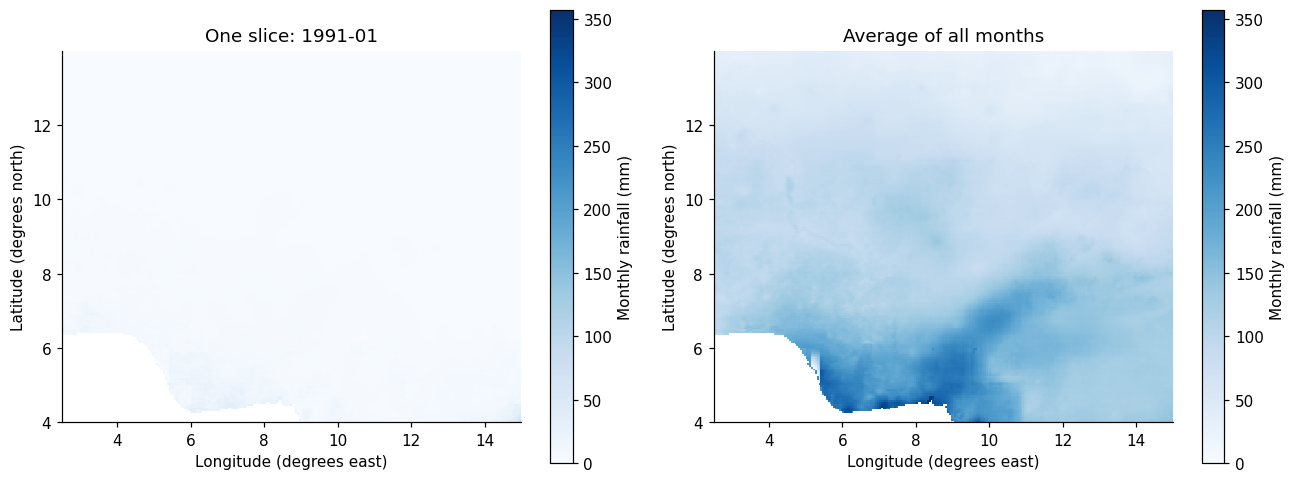

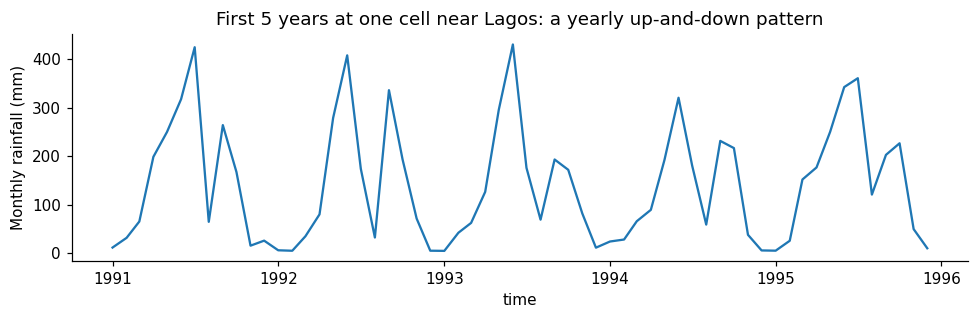

In [4]:
first_month = rain_dask.isel(time=0).compute()
average_map = rain_dask.mean("time").compute()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
shared_max = float(max(first_month.max(), average_map.max()))
first_month.plot(vmin=0, vmax=shared_max, ax=axes[0], cmap="Blues", cbar_kwargs={"label": "Monthly rainfall (mm)"})
axes[0].set_title("One slice: " + str(first_month.time.values)[:7])
average_map.plot(vmin=0, vmax=shared_max, ax=axes[1], cmap="Blues", cbar_kwargs={"label": "Monthly rainfall (mm)"})
axes[1].set_title("Average of all months")
for axis in axes:
    format_map(axis)
plt.tight_layout()
savefig("01_first_month_and_average.png")
plt.show()

# One location through time (nearest cell to Lagos), to see the yearly rhythm.
lagos = rain_dask.sel(latitude=6.5, longitude=3.4, method="nearest").compute()
lagos.isel(time=slice(0, 60)).plot(figsize=(9, 3))
plt.ylabel("Monthly rainfall (mm)")
plt.title("First 5 years at one cell near Lagos: a yearly up-and-down pattern")
plt.tight_layout()
savefig("02_one_location_time_series.png")
plt.show()

## 4. Data preparation: cleaning and checking

Negative rainfall values become missing. We reject intermittent missing values, infinities, duplicate or missing months, unexpected units and an empty study area. Always-missing cells are excluded coverage gaps; this check alone does not identify ocean.

Only after these checks do we calculate climatology, trends and complete seasonal totals. The array is small enough to load into memory; its size is printed below.


Rainfall array size: 80.1 MiB
Validated complete monthly calendar: 420
Intermittently missing cells: 0
Always-missing coverage gaps: 6.3%


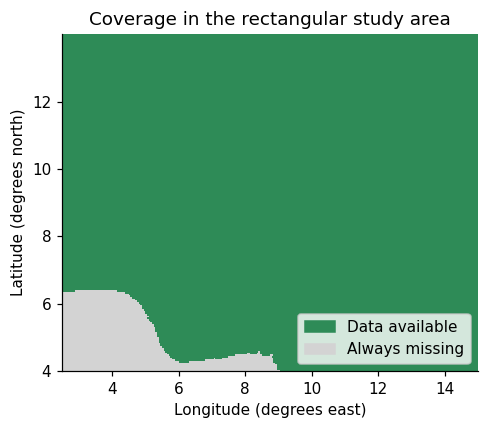

In [5]:
rain_dask = rain_dask.where(rain_dask >= 0)
rain = rain_dask.compute()
if bool(np.isinf(rain).any()):
    raise ValueError("Infinite rainfall values must be investigated.")
always_missing = rain.isnull().all("time")
partly_missing = rain.isnull().any("time") & ~always_missing
if bool(partly_missing.any()):
    raise ValueError("Intermittent missing rainfall: investigate before aggregation.")
if bool(always_missing.all()):
    raise ValueError("No usable rainfall cells in the study area.")
validate_dataset(rain.to_dataset(name="precip"))
print(f"Rainfall array size: {rain.nbytes / 1024**2:.1f} MiB")
print("Validated complete monthly calendar:", rain.sizes["time"])
print("Intermittently missing cells:", int(partly_missing.sum()))
print(f"Always-missing coverage gaps: {float(always_missing.mean()):.1%}")

coverage = (~always_missing).astype(int)
fig, ax = plt.subplots(figsize=(6, 4))
coverage.plot(ax=ax, cmap=ListedColormap(["lightgrey", "seagreen"]),
              vmin=0, vmax=1, add_colorbar=False)
ax.legend(handles=[Patch(color="seagreen", label="Data available"),
                   Patch(color="lightgrey", label="Always missing")], loc="lower right")
ax.set_title("Coverage in the rectangular study area")
format_map(ax)
fig.tight_layout()
savefig("03_land_mask.png")
plt.show()

## 5. Exploration (1): the normal year and the anomalies

**What we are doing:** finding what is *normal* for each calendar month, then measuring how far each real month is from normal.

**Technical terms:**
- **Climatology:** the long-term average for each calendar month. Twelve numbers per cell (the average January, the average February, and so on).
- **Anomaly:** *actual rainfall minus climatology*. Positive means wetter than normal, negative means drier than normal. Subtracting the climatology removes the seasons, so what is left is the unusual part. (This is *not* the outlier or fraud detection meaning of "anomaly".)

**What to look for:** compare the north and south curves to identify differences in rainfall amount and peak month. In the anomaly plots, wet and dry spells that stand out from the normal rhythm.

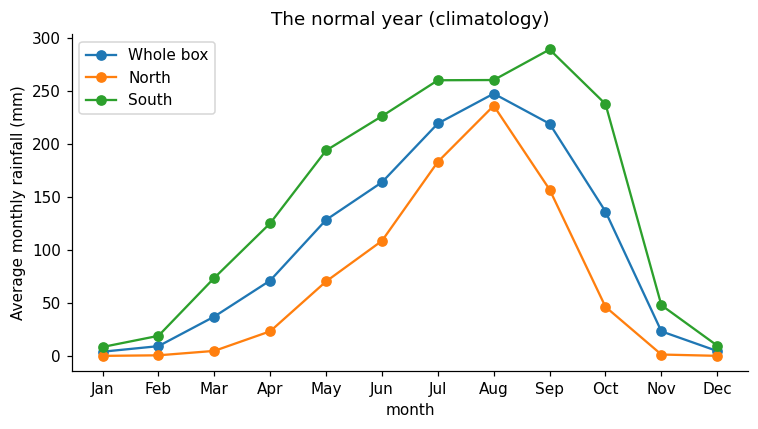

In [6]:
climatology = rain.groupby("time.month").mean("time")          # 12 maps: the normal for each month
anomalies = rain.groupby("time.month") - climatology                # actual minus normal


fig, ax = plt.subplots(figsize=(7, 4))
for label, part in [("Whole box", climatology), ("North", north(climatology)), ("South", south(climatology))]:
    regional_mean(part).plot(ax=ax, marker="o", label=label)
ax.set_xticks(range(1, 13), calendar.month_abbr[1:])
ax.set_ylabel("Average monthly rainfall (mm)")
ax.set_title("The normal year (climatology)")
ax.legend()
plt.tight_layout()
savefig("04_climatology_north_south.png")
plt.show()

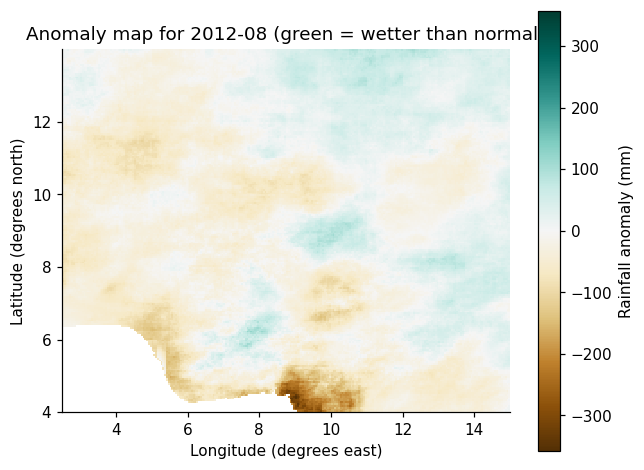

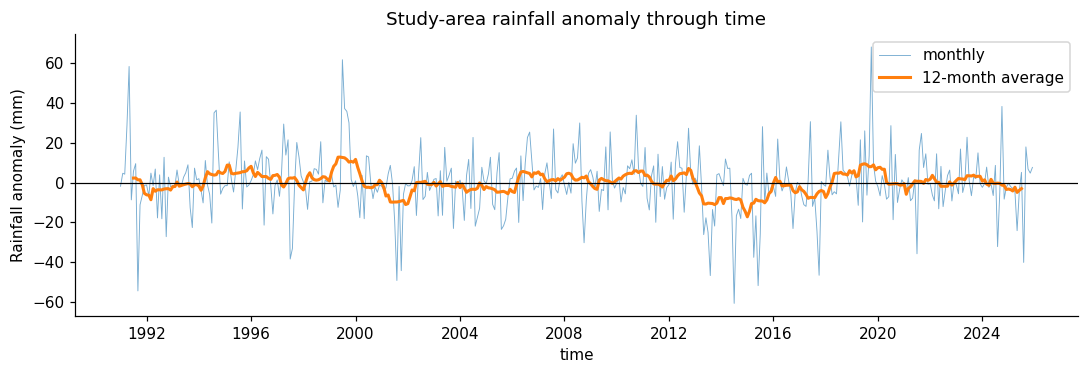

In [7]:
# A single month's anomaly map. 2012 was a year of major floods in Nigeria.
example_anomaly = anomalies.sel(time="2012-08-01", method="nearest")
vmax = float(np.nanmax(np.abs(example_anomaly.values)))
example_anomaly.plot(figsize=(6, 4.5), cmap="BrBG", vmin=-vmax, vmax=vmax, cbar_kwargs={"label": "Rainfall anomaly (mm)"})
format_map(plt.gca())
plt.title("Anomaly map for " + str(example_anomaly.time.values)[:7] + " (green = wetter than normal)")
plt.tight_layout()
savefig("05_anomaly_map_example.png")
plt.show()

# The whole story through time: study-area average anomaly, with a 12-month smooth line.
regional_anomaly = regional_mean(anomalies)
fig, ax = plt.subplots(figsize=(10, 3.5))
regional_anomaly.plot(ax=ax, lw=0.6, alpha=0.6, label="monthly")
regional_anomaly.rolling(time=12, center=True).mean().plot(ax=ax, lw=2, label="12-month average")
ax.set_ylabel("Rainfall anomaly (mm)")
ax.axhline(0, color="k", lw=0.8)
ax.legend()
ax.set_title("Study-area rainfall anomaly through time")
plt.tight_layout()
savefig("06_study-area_anomaly_series.png")
plt.show()

## 6. Exploration (2): the rainy season total

**What we are doing:** collapsing 12 months per year into a single number per year: the **total rainfall from June to September**, for every cell.

**Why:** a trend in single months is noisy. A seasonal total is a cleaner measure of "how wet was this rainy season". After this step the block is `year x latitude x longitude`.

**Complete seasons only:** `min_count=len(RAINY_MONTHS)` requires all four months. Coverage gaps stay missing instead of becoming zero rainfall.

**Limitation (important):** June to September fits the north best. The south has a longer, two-peaked season. We use one definition to keep the project simple, and say so honestly in the conclusions.

**Why June–September?** This project uses a fixed four-month window to compare the northern main rainy season consistently across years. The monthly climatology helps assess that choice. It does not measure the full rainy season everywhere: southern rainfall extends beyond this window. North–south comparisons here concern the same four months, not each region's complete annual rainy season.


Seasonal totals shape (year, latitude, longitude): (35, 200, 250)


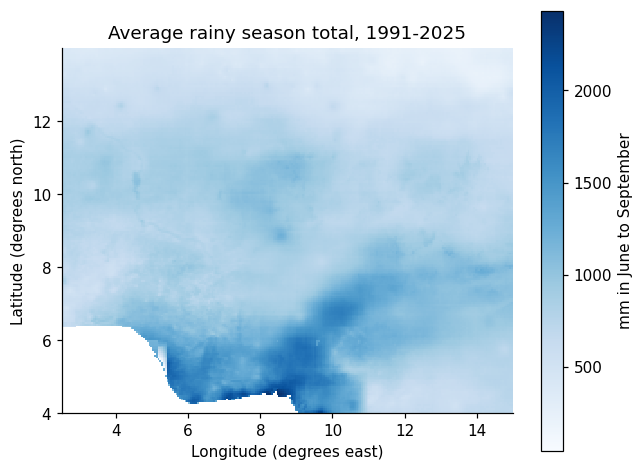

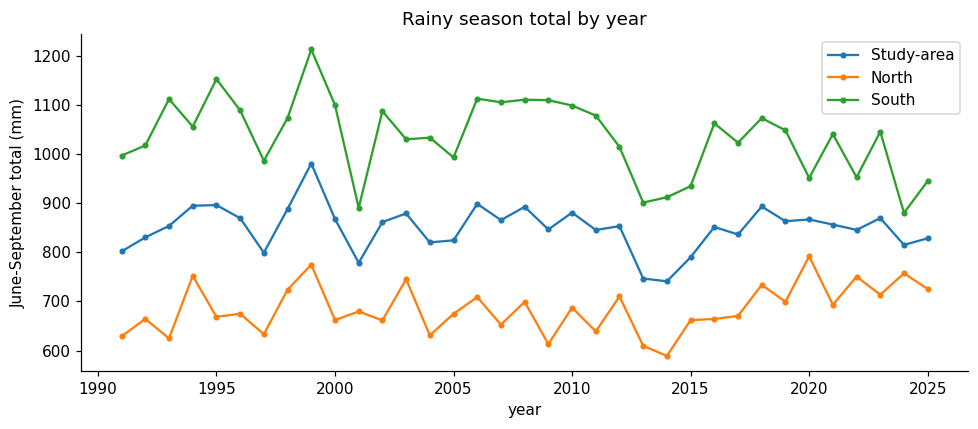

In [8]:
rainy = rain.sel(time=rain.time.dt.month.isin(RAINY_MONTHS))
seasonal = rainy.groupby("time.year").sum("time", min_count=len(RAINY_MONTHS))    # year x lat x lon

print("Seasonal totals shape (year, latitude, longitude):", seasonal.shape)

seasonal.mean("year").plot(figsize=(6, 4.5), cmap="Blues", cbar_kwargs={"label": "mm in June to September"})
format_map(plt.gca())
plt.title(f"Average rainy season total, {START[:4]}-{END[:4]}")
plt.tight_layout()
savefig("07_average_seasonal_total.png")
plt.show()

# Study-area, north and south time series of the seasonal total
study_area_seasonal = regional_mean(seasonal)
north_seasonal = regional_mean(north(seasonal))
south_seasonal = regional_mean(south(seasonal))
fig, ax = plt.subplots(figsize=(9, 4))
for label, s in [("Study-area", study_area_seasonal), ("North", north_seasonal), ("South", south_seasonal)]:
    ax.plot(s["year"], s, marker="o", ms=3, label=label)
ax.set_xlabel("year")
ax.set_ylabel("June-September total (mm)")
ax.legend()
ax.set_title("Rainy season total by year")
plt.tight_layout()
savefig("08_seasonal_series.png")
plt.show()

## 7. Trend analysis: where is seasonal rainfall changing?

For each cell, fit a straight line to its 35 yearly seasonal totals. Positive slope means increasing rainfall; negative means decreasing rainfall. Multiply the yearly slope by ten to express **mm per decade**.

The ordinary least-squares p-value assumes independent errors. We report raw p-values and apply **Benjamini–Hochberg false discovery rate selection at q = 0.05** for the second map. Under its dependence assumptions this controls the expected false-discovery proportion among selected tests; it does not require 5% of all cells to be selected.

Temporal autocorrelation is not explicitly modelled, and spatial dependence remains a limitation. The maps are exploratory evidence, not proof about each cell. The area-weighted average slope is descriptive without a separate significance test for that average.


**Residual dependence check:** after fitting the trend, compare each year's residual (observed minus fitted rainfall) with the preceding year's residual. Export cell-level lag-one correlation quantiles and regional lag-one correlations and Durbin–Watson statistics. These are descriptive diagnostics, without significance cutoffs. Small lag-one correlation does not rule out dependence at other lags. FDR addresses multiple comparisons; it does not repair p-values affected by serial correlation. Stronger inference requires a justified dependence model or a suitable block-resampling sensitivity analysis.

See the [statsmodels regression diagnostics guide](https://www.statsmodels.org/dev/diagnostic.html) for residual autocorrelation diagnostics. This notebook calculates the descriptive statistics directly without adding a package dependency.


C:\Users\PC\Downloads\climate-rainfall-nigeria\climate-rainfall-nigeria\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\PC\Downloads\climate-rainfall-nigeria\climate-rainfall-nigeria\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


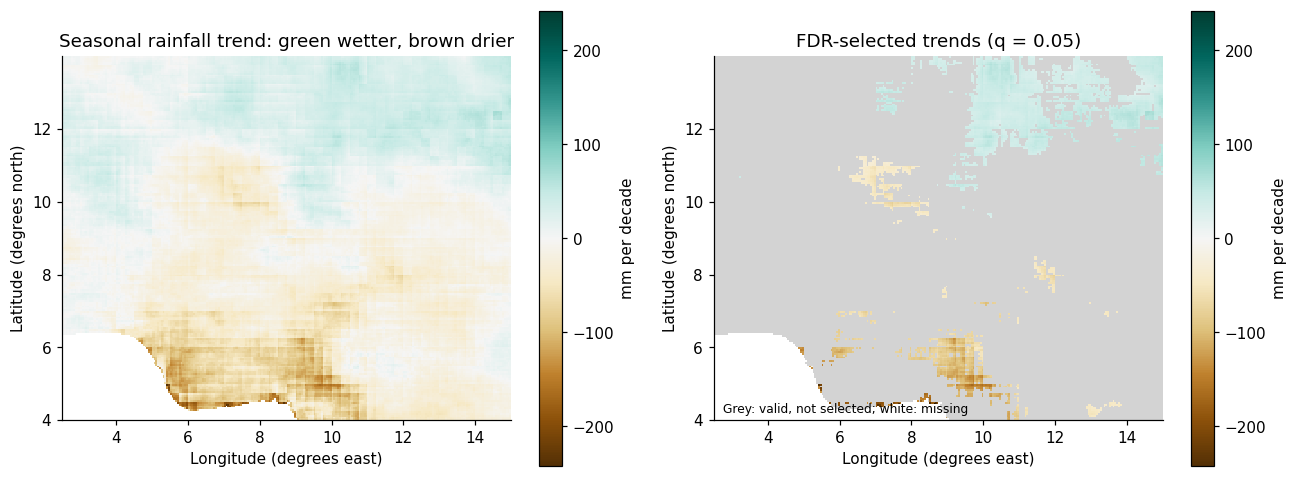

{
  "wetter_fraction": 0.4298545035627427,
  "drier_fraction": 0.5701454964372573,
  "fdr_selected_fraction": 0.11582113751760037,
  "mean_trend_mm_per_decade": -7.37463360338339
}
Raw p < 0.05: 30.4%


{
  "years": 35,
  "valid_cell_diagnostics": 46874,
  "cell_residual_lag1_quantiles": {
    "p05": -0.25925206542303475,
    "median": -0.002467557937611556,
    "p95": 0.26959322958381116
  },
  "interpretation": "Descriptive residual diagnostic only; trend p-values are not serial-correlation adjusted.",
  "regional_diagnostics": [
    {
      "region": "study_box",
      "years": 35,
      "residual_lag1_correlation": 0.3127533891235034,
      "durbin_watson": 1.3388009820759288
    },
    {
      "region": "north",
      "years": 35,
      "residual_lag1_correlation": 0.03453615502578379,
      "durbin_watson": 1.9147044010288765
    },
    {
      "region": "south",
      "years": 35,
      "residual_lag1_correlation": 0.17003037364944054,
      "durbin_watson": 1.612946799310847
    }
  ]
}


C:\Users\PC\Downloads\climate-rainfall-nigeria\climate-rainfall-nigeria\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\PC\Downloads\climate-rainfall-nigeria\climate-rainfall-nigeria\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [9]:
years = xr.DataArray(seasonal.year.values.astype(float), dims="year",
                     coords={"year": seasonal.year})
n_years = years.size
slope = xr.cov(seasonal, years, dim="year") / years.var("year", ddof=1)
correlation = xr.corr(seasonal, years, dim="year").clip(-1 + 1e-12, 1 - 1e-12)
t_statistic = correlation * np.sqrt((n_years - 2) / (1 - correlation**2))
p_value = xr.apply_ufunc(lambda value: 2 * stats.t.sf(np.abs(value), n_years - 2), t_statistic)
slope_decade = slope * 10
valid = slope_decade.notnull()

# Benjamini-Hochberg false discovery rate adjustment across valid cell tests.
finite = np.isfinite(p_value.values)
adjusted = np.full(p_value.shape, np.nan)
if finite.any():
    adjusted[finite] = stats.false_discovery_control(p_value.values[finite], method="bh")
adjusted_p = xr.DataArray(adjusted, dims=p_value.dims, coords=p_value.coords)
significant = adjusted_p <= SIGNIFICANCE
significant_uncorrected = p_value < SIGNIFICANCE

maximum = float(np.nanmax(np.abs(slope_decade.values)))
maximum = max(maximum, 1e-6)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for axis in axes:
    valid.where(valid).plot(ax=axis, cmap=ListedColormap(["lightgrey"]),
                           add_colorbar=False, add_labels=False, zorder=0)
slope_decade.plot(ax=axes[0], cmap="BrBG", vmin=-maximum, vmax=maximum,
                  cbar_kwargs={"label": "mm per decade"})
slope_decade.where(significant).plot(ax=axes[1], cmap="BrBG", vmin=-maximum,
                                     vmax=maximum, cbar_kwargs={"label": "mm per decade"})
axes[0].set_title("Seasonal rainfall trend: green wetter, brown drier")
axes[1].set_title(f"FDR-selected trends (q = {SIGNIFICANCE})")
axes[1].text(0.02, 0.02, "Grey: valid, not selected; white: missing",
             transform=axes[1].transAxes, fontsize=8)
for axis in axes:
    format_map(axis)
fig.tight_layout()
savefig("09_trend_maps.png")
plt.show()

trend_summary = {
    "wetter_fraction": float((slope_decade > 0).where(valid).mean()),
    "drier_fraction": float((slope_decade < 0).where(valid).mean()),
    "fdr_selected_fraction": float(significant.where(valid).mean()),
    "mean_trend_mm_per_decade": float(regional_mean(slope_decade))}
print(json.dumps(trend_summary, indent=2))
print(f"Raw p < {SIGNIFICANCE}: {float(significant_uncorrected.where(valid).mean()):.1%}")

# Check serial dependence after removing each cell's fitted linear trend.
# shift preserves calendar alignment: compare residual(t) with residual(t-1).
intercept = seasonal.mean("year") - slope * years.mean("year")
residuals = seasonal - (intercept + slope * years)
residual_lag1 = xr.corr(residuals, residuals.shift(year=1), dim="year")
finite_lag1 = residual_lag1.values[np.isfinite(residual_lag1.values)]
autocorrelation_summary = {
    "years": int(n_years),
    "valid_cell_diagnostics": int(finite_lag1.size),
    "cell_residual_lag1_quantiles": dict(zip(
        ["p05", "median", "p95"],
        np.quantile(finite_lag1, [0.05, 0.5, 0.95]).tolist())),
    "interpretation": "Descriptive residual diagnostic only; trend p-values are not serial-correlation adjusted."
}
regional_diagnostics = []
for name, region in [
    ("study_box", seasonal),
    ("north", seasonal.where(seasonal.latitude >= NORTH_SOUTH_SPLIT)),
    ("south", seasonal.where(seasonal.latitude < NORTH_SOUTH_SPLIT)),
]:
    series = regional_mean(region).values
    fit = stats.linregress(years.values, series)
    residual = series - (fit.intercept + fit.slope * years.values)
    regional_diagnostics.append({
        "region": name,
        "years": int(n_years),
        "residual_lag1_correlation": float(np.corrcoef(residual[:-1], residual[1:])[0, 1]),
        "durbin_watson": float(np.sum(np.diff(residual)**2) / np.sum(residual**2)),
    })
autocorrelation_summary["regional_diagnostics"] = regional_diagnostics
(RES_DIR / "trend_autocorrelation.json").write_text(
    json.dumps(autocorrelation_summary, indent=2), encoding="utf-8")
print(json.dumps(autocorrelation_summary, indent=2))


### Dask check: numerical consistency on this dataset

The same trend calculation is run with chunked Dask arrays and in memory. The assertion verifies agreement within numerical tolerance. Timings describe this local run only: the in-memory data is already loaded, while Dask may include reads and scheduling overhead. This is not a controlled benchmark or evidence that the entire workflow scales efficiently. Larger-data performance requires measuring memory, chunk sizes, I/O and execution time on representative workloads.


In [10]:
def compute_trend(da):
    """Compute an annual slope using complete seasonal totals."""
    da = da.where(da >= 0)
    season = da.sel(time=da.time.dt.month.isin(RAINY_MONTHS))
    totals = season.groupby("time.year").sum("time", min_count=len(RAINY_MONTHS))
    yr = xr.DataArray(totals["year"].values.astype(float), dims="year",
                      coords={"year": totals["year"]})
    return xr.cov(totals, yr, dim="year") / yr.var("year", ddof=1)

t0 = time.perf_counter()
slope_dask = compute_trend(rain_dask).compute()
t_dask = time.perf_counter() - t0
t0 = time.perf_counter()
slope_mem = compute_trend(rain)
t_mem = time.perf_counter() - t0

print(f"dask (chunked): {t_dask:.2f} s | in memory: {t_mem:.2f} s")
np.testing.assert_allclose(slope_dask.values, slope_mem.values, rtol=1e-6, atol=1e-8, equal_nan=True)
print("Dask and in-memory slopes agree within numerical tolerance.")

dask (chunked): 2.42 s | in memory: 0.32 s
Dask and in-memory slopes agree within numerical tolerance.


## 8. Modelling (prediction) and evaluation: can we forecast next year's total?

**What we are doing:** trying to predict the **study-area rainy season total** of a year using only information from *earlier* years.

**The setup:**
- **Target (what we predict):** the study-area average June to September total for year *t*.
- **Features (what we use):** rainfall from earlier years. A **lag feature** is a past value used as an input. `lag1` means last year's total.
- **Four models, from simplest to a little less simple:**
  1. **Baseline (climatology):** always predict the average of all past years. *Every real model must beat this to be useful.*
  2. **Persistence:** predict that this year equals last year.
  3. **Linear on lag1:** a straight-line model using last year's total.
  4. **Linear on year (trend):** a straight-line model using only the year number.

**How we test it (very important):** this is time-ordered data, so we may **not** shuffle and split randomly, because that would let the model "see the future". We use **walk-forward validation**:
for each test year from 2011 to 2025, train *only* on years before it, predict that year, then move one year forward.

**Metrics:**
- **MAE** (mean absolute error): the average size of the error, in mm.
- **RMSE** (root mean squared error): like MAE but punishes large errors more.
- **Skill score:** `1 - MSE_model / MSE_baseline`. Above 0 means better than the baseline, 0 means no better, below 0 means worse.

**Expect a small sample:** only about 35 yearly values exist, so conclusions here are weak. That is normal and should be reported honestly.

**One continuous evaluation:** the file contains 1991–2025, but the 2025 prediction uses observations through 2024 only. There is no separate 2025 experiment. The baseline uses every earlier year. Both regressions use the shared lag-feature table, so their target years begin in 1992, with 1991 providing the first previous-year value.

The climatology and trend maps use the full record for description. Forecasting uses raw seasonal totals from earlier years only, so full-period climatology does not leak into predictions. These are retrospective forecast tests, not forecasts issued before the seasons occurred.


In [11]:
y = study_area_seasonal.to_series()
y.index = y.index.astype(int)
forecast_data = pd.DataFrame({"y": y, "lag1": y.shift(1), "year": y.index}).dropna()

rows = []
for test_year in range(FIRST_TEST_YEAR, int(forecast_data.index.max()) + 1):
    train = forecast_data[forecast_data.index < test_year]
    test = forecast_data.loc[[test_year]]
    assert train.index.max() < test_year

    pred_base = y.loc[y.index < test_year].mean()
    pred_persist = float(test["lag1"].iloc[0])

    m_lag = LinearRegression().fit(train[["lag1"]], train["y"])
    pred_lag = float(m_lag.predict(test[["lag1"]])[0])

    m_trend = LinearRegression().fit(train[["year"]], train["y"])
    pred_trend = float(m_trend.predict(test[["year"]])[0])

    rows.append({"year": test_year, "actual": float(test["y"].iloc[0]),
                 "baseline": pred_base, "persistence": pred_persist,
                 "linear_lag1": pred_lag, "linear_trend": pred_trend})

preds = pd.DataFrame(rows).set_index("year")

mse_base = ((preds["actual"] - preds["baseline"]) ** 2).mean()
if mse_base == 0:
    raise ValueError("Baseline error is zero; relative skill is undefined.")

table = []
for model in ["baseline", "persistence", "linear_lag1", "linear_trend"]:
    err = preds["actual"] - preds[model]
    table.append({"model": model,
                  "MAE": err.abs().mean(),
                  "RMSE": np.sqrt((err ** 2).mean()),
                  "skill_vs_baseline": 1 - (err ** 2).mean() / mse_base})
metrics = pd.DataFrame(table).set_index("model").round(3)
metrics.to_csv(RES_DIR / "metrics.csv")
preds.round(1).to_csv(RES_DIR / "forecast_predictions.csv")

print(f"Walk-forward test years: {FIRST_TEST_YEAR} to {preds.index.max()} ({len(preds)} forecasts)")
print(metrics)

Walk-forward test years: 2011 to 2025 (15 forecasts)
                 MAE    RMSE  skill_vs_baseline
model                                          
baseline      32.793  48.286              0.000
persistence   32.368  42.651              0.220
linear_lag1   30.812  45.740              0.103
linear_trend  38.769  49.703             -0.060


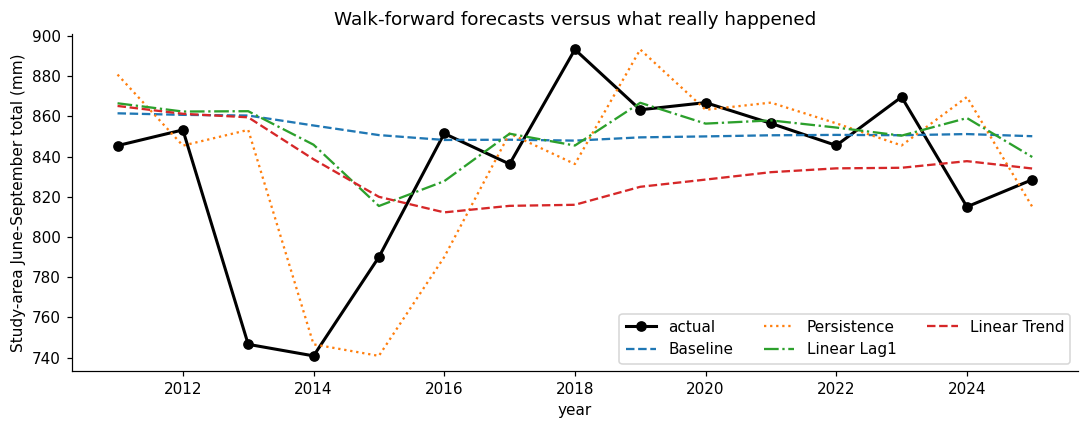

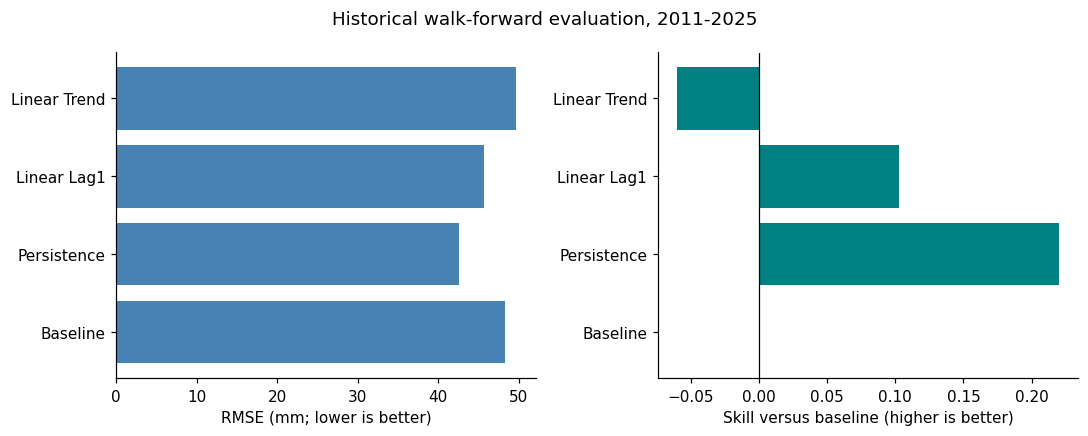

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(preds.index, preds["actual"], "k-o", lw=2, label="actual")
for model, style in [("baseline", "--"), ("persistence", ":"), ("linear_lag1", "-."), ("linear_trend", "--")]:
    ax.plot(preds.index, preds[model], style, label=model.replace("_", " ").title())
ax.set_xlabel("year")
ax.set_ylabel("Study-area June-September total (mm)")
ax.set_title("Walk-forward forecasts versus what really happened")
ax.legend(ncol=3)
plt.tight_layout()
savefig("10_forecast_vs_actual.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
labels = [model.replace("_", " ").title() for model in metrics.index]
axes[0].barh(labels, metrics.RMSE, color="steelblue")
axes[0].set_xlabel("RMSE (mm; lower is better)")
axes[1].barh(labels, metrics.skill_vs_baseline, color="teal")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Skill versus baseline (higher is better)")
fig.suptitle(f"Historical walk-forward evaluation, {FIRST_TEST_YEAR}-{preds.index.max()}")
fig.tight_layout()
savefig("11_forecast_metrics.png")
plt.show()

**Interpretation:** positive skill means a method reduced mean squared error against the historical-mean baseline over these 15 test years. It is not a guarantee of future accuracy. Negative skill means it did worse than that baseline in this comparison.

The best method depends on the error metric. A method winning in 2025 alone need not be the best across all 15 years. Future work could add ocean-temperature predictors or evaluate separate subregions. Daily data alone do not create more independent seasonal forecast targets.


## 9. Findings, limitations and reproducibility

The 1991–2025 mean June–September total is **849.6 mm** across the study box: **684.8 mm** in the north and **1035.3 mm** in the south. Monthly climatology peaks in August for the box and north, and September for the south.

The area-weighted mean trend is **−7.4 mm per decade**. FDR selection at q = 0.05 selects **11.6%** of valid cells; this does not establish significance for the area-average trend.

Across the **15 historical predictions (2011–2025)**, persistence has the lowest RMSE (**42.651 mm**) and reduces mean squared error by **22.0%** against the historical-mean baseline. Lag regression has the lowest MAE (**30.812 mm**). These results describe this historical sample, not guaranteed future accuracy.

**Limitations:** the rectangle includes neighbouring countries; June–September best matches the northern main season; CHIRPS has observational uncertainty; trend tests have independence assumptions; and 15 historical forecast years are a limited sample. No future forecast is issued.


**Attribution:** observed trends describe changes in this rainfall record. They do not establish that human-caused climate change produced those changes. Attribution requires additional evidence and analysis of competing drivers.


**Residual diagnostic results:** lag-one residual correlation is 0.313 for the study box, 0.035 for the north and 0.170 for the south. The cell-level median is -0.002 (5th–95th percentiles: -0.259 to 0.270). These descriptive values do not validate independence or adjust the trend p-values.


**Temporal-dependence sensitivity:** the final cell exports a Newey–West/HAC comparison using Bartlett weights, lag windows of 1, 3 and 5 years, covariance correction n/(n−2), and an approximate t(n−2) reference. The windows are fixed sensitivity choices, not selected to maximize significance. The 3-year choice also matches the statsmodels default bandwidth formula for 35 observations. The slopes stay unchanged; uncertainty estimates change. The vectorized implementation is cross-checked against statsmodels fits at 12 representative cells for each window.

BH-selected fractions are **11.6% (OLS), 15.7% (HAC lag 1), 20.6% (lag 3), and 23.4% (lag 5)**. These differences demonstrate method sensitivity, not definitive evidence of change. HAC can increase or decrease standard errors. With only 35 annual values, approximate inference, bandwidth dependence and spatial dependence remain limitations. The existing map continues to show OLS-based BH selection; the separate sensitivity tables include cell selections and regional trend intervals.

Method reference: [statsmodels HAC covariance documentation](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html).


In [13]:
packages = ["numpy", "pandas", "xarray", "netCDF4", "dask", "scipy",
            "scikit-learn", "matplotlib", "jupyterlab", "ipykernel", "nbclient",
            "nbformat", "fsspec", "h5py", "aiohttp", "statsmodels"]
environment = {package: version(package) for package in packages}
environment.update(python=sys.version.split()[0], operating_system=platform.system())
(RES_DIR / "environment.json").write_text(json.dumps(environment, indent=2))
best_model = metrics.RMSE.idxmin()
summary = {
    "scope": STUDY_LABEL, "period": [START, END],
    "mean_seasonal_rainfall_mm": float(study_area_seasonal.mean("year")),
    "peak_calendar_month": int(regional_mean(climatology).idxmax("month")),
    "north_mean_seasonal_mm": float(north_seasonal.mean("year")),
    "south_mean_seasonal_mm": float(south_seasonal.mean("year")),
    "north_peak_month": int(regional_mean(north(climatology)).idxmax("month")),
    "south_peak_month": int(regional_mean(south(climatology)).idxmax("month")),
    "valid_cells": int(valid.sum()), "partly_missing_cells": int(partly_missing.sum()),
    "trend": trend_summary, "best_historical_model": best_model,
    "forecast_metrics": metrics.loc[best_model].to_dict(), "test_years": len(preds),
    "note": "Historical evaluation only; no future forecast is issued."}
(RES_DIR / "analysis_summary.json").write_text(json.dumps(summary, indent=2))
with DATA_FILE.open("rb") as source_file:
    checksum = hashlib.file_digest(source_file, "sha256").hexdigest()
manifest = {"file": str(DATA_FILE), "bytes": DATA_FILE.stat().st_size,
            "sha256": checksum, "source": ds.attrs.get("source", SOURCE),
            "product": "CHIRPS v2.0 monthly, 0.05 degree", "period": [START, END],
            "bounds": {"latitude": [LAT_MIN, LAT_MAX], "longitude": [LON_MIN, LON_MAX]}}
(RES_DIR / "data_manifest.json").write_text(json.dumps(manifest, indent=2))
print(json.dumps(summary, indent=2))
print(json.dumps(environment, indent=2))
ds.close()

# Reconstruct forecasts independently and compare dependence-aware inference.
from verify_analysis import main as verify_analysis
from verify_spatial_weights import main as verify_spatial_weights
verify_analysis()
verify_spatial_weights()


{
  "scope": "Nigeria study box (includes neighbouring countries)",
  "period": [
    "1991-01-01",
    "2025-12-01"
  ],
  "mean_seasonal_rainfall_mm": 849.5511474609375,
  "peak_calendar_month": 8,
  "north_mean_seasonal_mm": 684.8231811523438,
  "south_mean_seasonal_mm": 1035.3114013671875,
  "north_peak_month": 8,
  "south_peak_month": 9,
  "valid_cells": 46874,
  "partly_missing_cells": 0,
  "trend": {
    "wetter_fraction": 0.4298545035627427,
    "drier_fraction": 0.5701454964372573,
    "fdr_selected_fraction": 0.11582113751760037,
    "mean_trend_mm_per_decade": -7.37463360338339
  },
  "best_historical_model": "persistence",
  "forecast_metrics": {
    "MAE": 32.368,
    "RMSE": 42.651,
    "skill_vs_baseline": 0.22
  },
  "test_years": 15,
  "note": "Historical evaluation only; no future forecast is issued."
}
{
  "numpy": "2.3.5",
  "pandas": "2.3.3",
  "xarray": "2025.10.1",
  "netCDF4": "1.7.4",
  "dask": "2025.11.0",
  "scipy": "1.16.3",
  "scikit-learn": "1.7.2",
  "mat

{
  "forecast_years": 15,
  "forecast_predictions_verified": true,
  "forecast_metrics_verified": true,
  "hac_library_cross_checks": 36,
  "method": "Newey-West HAC, Bartlett kernel, lags 1/3/5, n/(n-2) correction, approximate t(n-2) inference; BH q=0.05 separately per method.",
  "limitations": "Sensitivity analysis, not definitive inference. Small sample, bandwidth choice, temporal model and spatial dependence remain limitations. HAC may increase or decrease standard errors.",
  "trend_comparison": [
    {
      "method": "OLS",
      "valid_cells": 46874,
      "raw_p_below_005_fraction": 0.3038998165294193,
      "bh_fdr_selected_fraction": 0.11582113751760037,
      "selected_by_both_ols_and_method_fraction": 0.11582113751760037,
      "selection_changed_from_ols_fraction": 0.0
    },
    {
      "method": "HAC_lag1",
      "valid_cells": 46874,
      "raw_p_below_005_fraction": 0.324124247983957,
      "bh_fdr_selected_fraction": 0.1572300209071127,
      "selected_by_both_ols_a

{
  "total_cells": 50000,
  "valid_cells": 46874,
  "permanently_missing_cells": 3126,
  "intermittently_missing_cells": 0,
  "regions": [
    {
      "region": "study_box",
      "valid_cells": 46874,
      "available_area_fraction": 0.9368615896672876,
      "maximum_monthly_mean_difference_mm": 0.000443974314521256
    },
    {
      "region": "north",
      "valid_cells": 25000,
      "available_area_fraction": 1.0,
      "maximum_monthly_mean_difference_mm": 0.0003517744011105606
    },
    {
      "region": "south",
      "valid_cells": 21874,
      "available_area_fraction": 0.8745904131771962,
      "maximum_monthly_mean_difference_mm": 0.0003285561676875659
    }
  ],
  "scope": "Rectangular study area; no Nigeria boundary mask. Missing coverage is not classified as land or ocean."
}
